# DBSCAN++ : un clustering par densité qui passe à l'échelle

[![Ouvrir dans Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/moncoachdata/cercle-des-experts/blob/main/ml-classique-et-deep-learning/dbscan-plus-plus-clustering-scalable/dbscan-plus-plus-clustering-scalable.ipynb)

📖 **Le mini-cours complet** : [DBSCAN++ : Passe ton Clustering à l'échelle supérieure](https://www.monshotdata.com/p/dbscan-plus-plus-clustering-scalable)

🧭 **Le cours** : [ML classique et Deep Learning › 2.3 Clustering et réduction de dimension](https://www.monshotdata.com/mini-cours/ml-classique-et-deep-learning#h2sc23)

---

DBSCAN sait trouver des clusters de n'importe quelle forme, mais son temps de calcul explose avec le nombre de points. **DBSCAN++** ne calcule la densité que sur un **échantillon** de points : beaucoup plus rapide, et avec le bon échantillonnage, aussi précis. Tu vas l'implémenter, le tester sur deux jeux de données et mesurer ce qui coûte cher dans DBSCAN.

**À la fin de ce notebook, tu sauras :**

- comment DBSCAN++ remplace le calcul de densité sur tous les points par un calcul sur un échantillon ;
- pourquoi l'échantillonnage par **k-centres** donne de bien meilleurs clusters que l'échantillonnage aléatoire ;
- comment mesurer le temps d'exécution de DBSCAN et voir sa croissance quand les données grossissent.


### Avant de lancer

Le jeu de données *Smiley* (`smiley_face.pickle`, quelques Ko) est téléchargé automatiquement depuis le dépôt GitHub. Pas de GPU. **Exécution → Tout exécuter** : environ une minute ; les graphiques sont nombreux car chaque expérience est répétée plusieurs fois (le hasard de l'échantillonnage change le résultat).

**Deux corrections par rapport à la version diffusée avec le mini-cours :** `self.epsilon` lisait une variable globale au lieu du paramètre `eps`, et les points non assignés recevaient l'étiquette 0 au lieu de -1. Les résultats restent qualitativement les mêmes.

🧪 *Testé le 20 novembre 2026 avec Python 3.13, NumPy, pandas, scikit-learn et Matplotlib dans leurs versions de Colab.*

## 1. Mise en place

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

from sklearn.cluster import DBSCAN
from sklearn.datasets import make_moons

sns.set()

In [2]:
colors = ['#fe7c73', '#2471A3', '#3498DB', '#27AE60', '#82E0AA', '#D35400', '#5D6D7E', '#E74C3C', '#21618C', '#B7950B', '#46C7C7', '#00B9FF', '#FF7051', "orange", "darkorange", "tomato", "coral", "limegreen", "lightsalmon"]
plt.rcParams['font.family'] = ['Comic Sans MS', 'sans-serif']

## 2. L'algorithme DBSCAN++

La classe `DBSCANpp` suit les cinq étapes du mini-cours :

1. **Échantillonner** `m` points de départ (aléatoirement, ou par *k-centres* : on choisit à chaque fois le point le plus éloigné de ceux déjà choisis, pour couvrir tout l'espace) ;
2. **Trouver les points cœurs** parmi cet échantillon : ceux qui ont au moins `min_pts` voisins dans un rayon `eps` ;
3. **Lancer DBSCAN** sur ces seuls points cœurs ;
4. **Étendre** les clusters : chaque point proche (rayon `eps`) d'un point cœur prend son cluster ;
5. Les points restants sont du **bruit** (étiquette -1).

In [3]:
class DBSCANpp:
    def __init__(self, m, eps, min_pts, sampling = "random"):
        
        self.sampling = sampling
        self.m = m
        self.epsilon = eps
        self.min_pts = min_pts
        self.core_dbscan = DBSCAN(eps=self.epsilon, min_samples=self.min_pts)

    def fit(self, X):
        # Échantillonner des points pour obtenir S
        
        if self.sampling == "random":
            self.S = self._random_init(X)
        elif self.sampling == "kcenter":
            self.S = self._kcenter_init(X)
        else:
            raise ValueError("Valeur invalide pour la méthode d'initialisation")

        # Trouver les points cœur C dans l’échantillon S
        self.core_points = self._find_core_points(X, self.S)

        # Exécuter DBSCAN sur les points cœur C
        core_labels = self._run_dbscan_core()
        
        # Attribuer un label de cluster à tous les points en fonction des clusters des points cœur
        cluster_labels = self._assign_to_core(X, core_labels)

        return cluster_labels
    
    def _run_dbscan_core(self):
        
        return self.core_dbscan.fit_predict(self.S[self.core_points])
        
    def _random_init(self, X):
        S_indices = np.random.choice(len(X), self.m, replace=False)
        return X[S_indices]
        
    def _kcenter_init(self, X):
        n = len(X)
        S = np.zeros((self.m, X.shape[1]))
        
        # Choisir aléatoirement le premier point
        S[0] = X[np.random.choice(n)]
        
        for i in range(1, self.m):
            # Trouver le point de X qui maximise la distance minimale aux centres actuels dans S
            distances = np.linalg.norm(X[:, np.newaxis, :] - S[:i], axis=2)
            
            distances[distances == 0] = -np.inf
            
            min_distances = np.min(distances, axis=1)
            max_distance_index = np.argmax(min_distances)
            S[i] = X[max_distance_index]

        return S

    def _find_core_points(self, X, S):
        # Trouver les points cœur dans l’échantillon S
        distances = np.linalg.norm(X[:, np.newaxis, :] - S, axis=2)
    
        mask = np.sum(distances <= self.epsilon, axis=0) >= self.min_pts
        
        core_points = np.where(mask)[0]
        return core_points

    def _assign_to_core(self, X, core_labels):
        
        cluster_labels = -np.ones(len(X), dtype=int)
        unique_core_labels = np.unique(core_labels)
        
        for label in unique_core_labels:
            core_indices = self.core_points[core_labels == label]
            core_points = self.S[core_indices]
            distances = np.linalg.norm(X[:, np.newaxis, :] - core_points, axis=2)
            neighbors_condition = np.any(distances <= self.epsilon, axis=1)
            neighbors = np.where(neighbors_condition)[0]
            
            cluster_labels[neighbors] = label        
        
        return cluster_labels

## 3. Expérience n°1 : le jeu de données « Moons »

Deux demi-lunes entrelacées, un classique que k-means ne sait pas séparer.

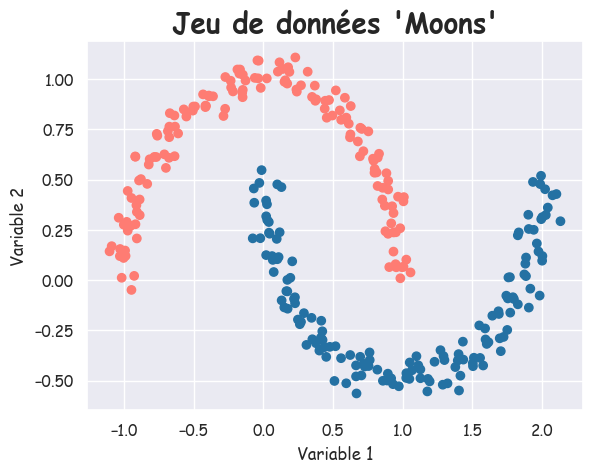

In [4]:
# Supposons que X soit ton jeu de données (tableau NumPy) et n le nombre de points de données
X, y = make_moons(n_samples=300, noise=0.05, random_state=42)

fig, ax = plt.subplots()
ax.scatter(X[:, 0], X[:, 1], c=[colors[i] for i in y])
plt.title("Jeu de données 'Moons'", fontsize=20, weight="bold")
plt.xlabel("Variable 1")
plt.ylabel("Variable 2")
plt.show()

### 3.1 Échantillonnage aléatoire

On répète le clustering 5 fois avec `m = 50` points tirés au hasard. Les cercles roses montrent le rayon `eps` autour de chaque point cœur retenu. Résultat : selon le tirage, quelques points sont mal assignés, car l'échantillon contient parfois trop peu de points cœurs. **Répéter l'algorithme aide.**

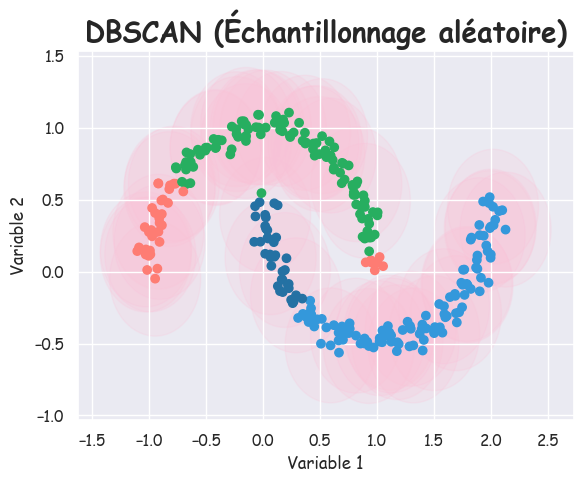

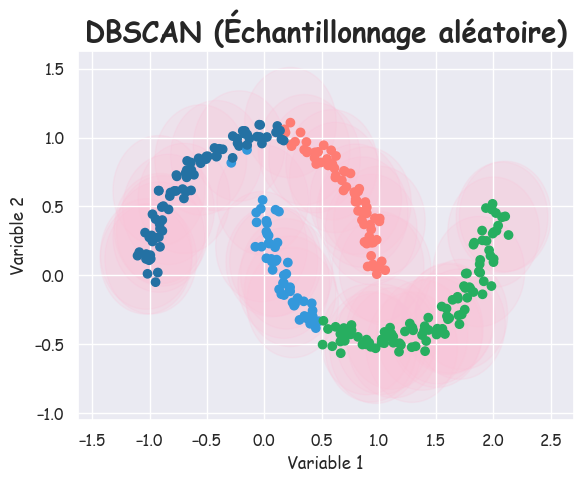

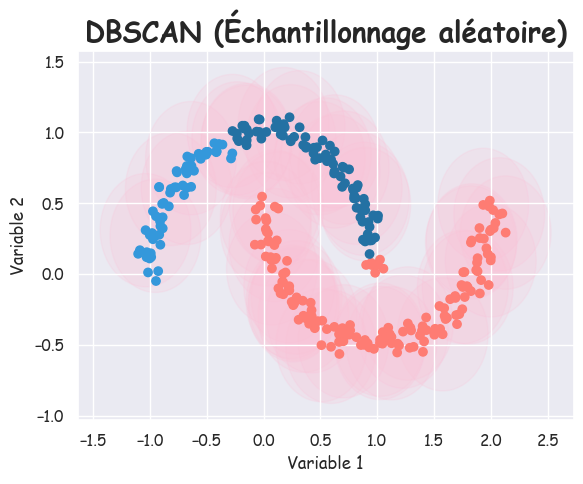

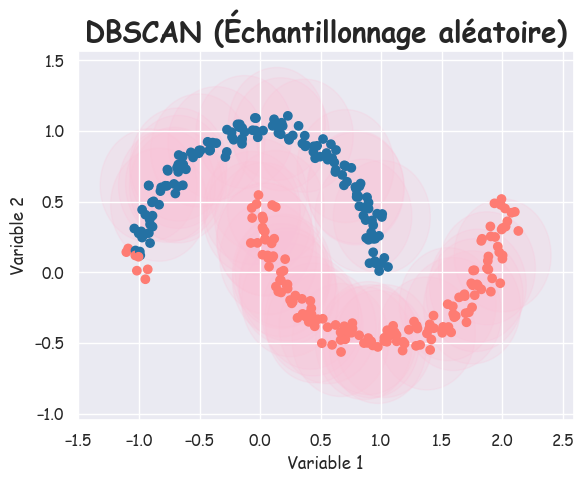

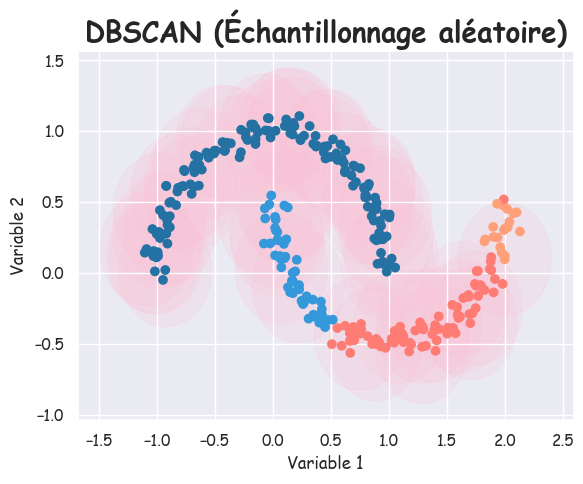

In [5]:
# Supposons que X soit ton jeu de données (tableau NumPy) et n le nombre de points de données
X, y = make_moons(n_samples=300, noise=0.05, random_state=42)
n = len(X)
epsilon = 0.4
m = 50

for j in range(5):
    # Créer un objet DBSCANpp
    dbscan_pp = DBSCANpp(m=m, eps=epsilon, min_pts=2)

    # Ajuster le modèle et obtenir les clusters
    clusters = dbscan_pp.fit(X)

    fig, ax = plt.subplots()

    ax.scatter(X[:, 0], X[:, 1], c=[colors[i] for i in clusters])

    for i in dbscan_pp.S[dbscan_pp.core_points]:
        circle1 = plt.Circle((i[0], i[1]), epsilon, color='#fcc2d7', alpha=0.2, zorder=0)
        ax.add_patch(circle1)

    plt.title("DBSCAN (Échantillonnage aléatoire)", fontsize=20, weight="bold")
    plt.xlabel("Variable 1")
    plt.ylabel("Variable 2")
    plt.show()

### 3.2 Échantillonnage par k-centres

Ici on prend `m = n` (tous les points sont candidats) pour montrer l'effet du choix des centres : l'échantillon couvre uniformément l'espace, et les deux lunes sont correctement séparées.

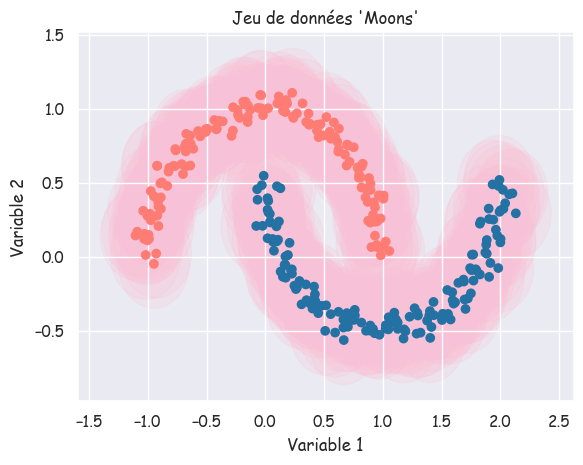

In [7]:
# Supposons que X soit ton jeu de données (tableau NumPy) et n le nombre de points de données
X, y = make_moons(n_samples=300, noise=0.05, random_state=42)
n = len(X)
epsilon = 0.3
m = len(X)

# Créer un objet DBSCANpp
dbscan_pp = DBSCANpp(m=m, eps=epsilon, min_pts=2, sampling="kcenter")

# Ajuster le modèle et obtenir les clusters
clusters = dbscan_pp.fit(X)

fig, ax = plt.subplots()

ax.scatter(X[:, 0], X[:, 1], c=[colors[i] for i in clusters])

for i in dbscan_pp.S[dbscan_pp.core_points]:
    circle1 = plt.Circle((i[0], i[1]), epsilon, color='#fcc2d7', alpha=0.2, zorder=0)
    ax.add_patch(circle1)

plt.title("Jeu de données 'Moons'")
plt.xlabel("Variable 1")
plt.ylabel("Variable 2")
plt.show()

## 4. Expérience n°2 : le jeu de données « Smiley »

Un visage souriant : quatre groupes de formes très différentes (deux yeux, un nez, une bouche). Les données sont téléchargées depuis le dépôt si elles ne sont pas déjà présentes.

In [ ]:
# Télécharge les fichiers nécessaires depuis le dépôt GitHub s'ils ne sont pas déjà présents
import os, urllib.request

BASE = "https://raw.githubusercontent.com/moncoachdata/cercle-des-experts/main/ml-classique-et-deep-learning/dbscan-plus-plus-clustering-scalable"
for f in ['smiley_face.pickle']:
    if not os.path.exists(f):
        os.makedirs(os.path.dirname(f) or ".", exist_ok=True)
        urllib.request.urlretrieve(f"{BASE}/{f}", f)

In [8]:
df = pd.read_pickle("smiley_face.pickle")
X = df.values
print(X.shape)

(623, 2)


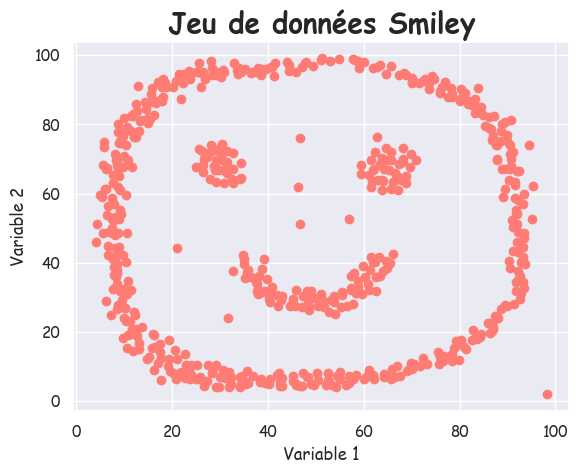

In [9]:
fig, ax = plt.subplots()
ax.scatter(X[:, 0], X[:, 1], c=colors[0])
plt.title("Jeu de données Smiley", fontsize=20, weight="bold")
plt.xlabel("Variable 1")
plt.ylabel("Variable 2")
plt.show()

### 4.1 Échantillonnage aléatoire (6 essais)

Avec 200 points tirés au hasard, les résultats varient fortement d'un essai à l'autre : parfois les yeux fusionnent avec le visage, parfois un cluster est coupé.

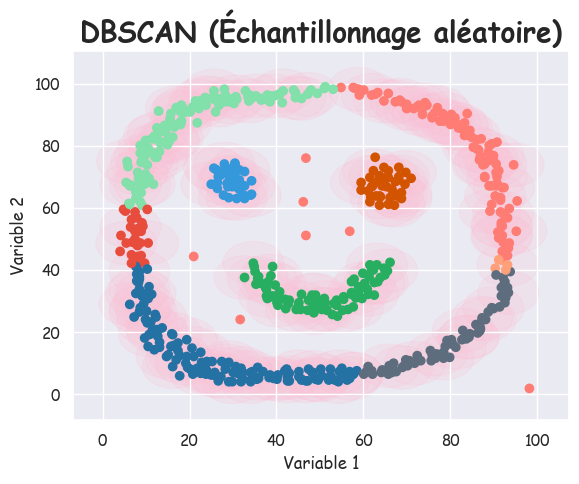

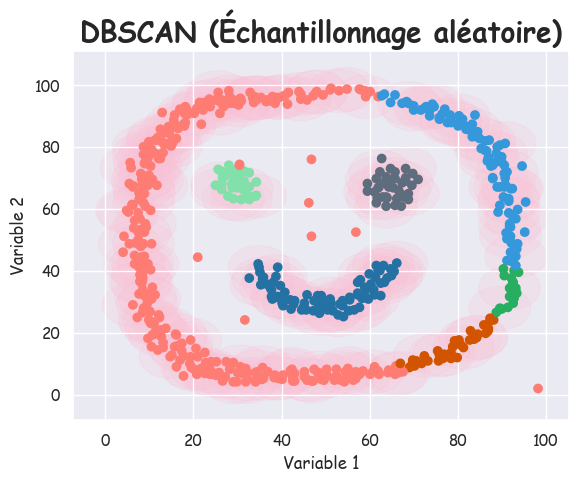

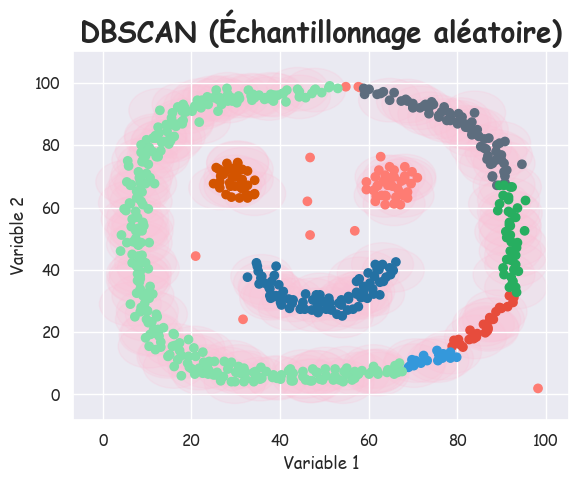

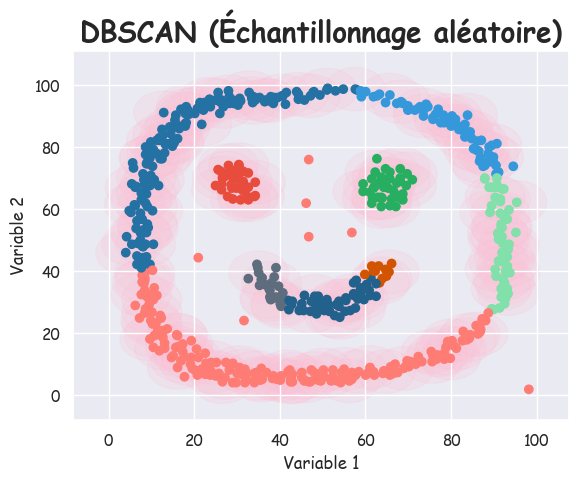

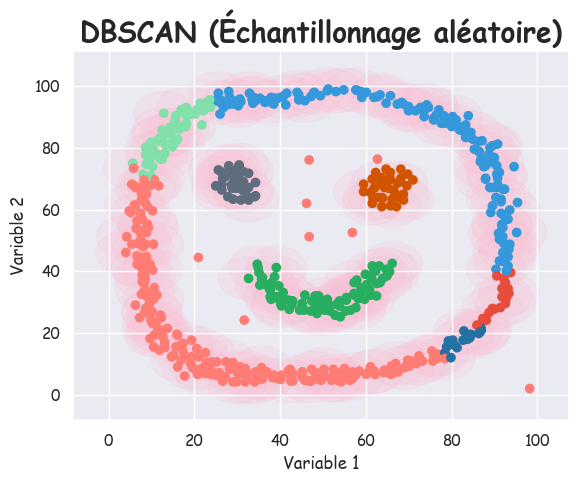

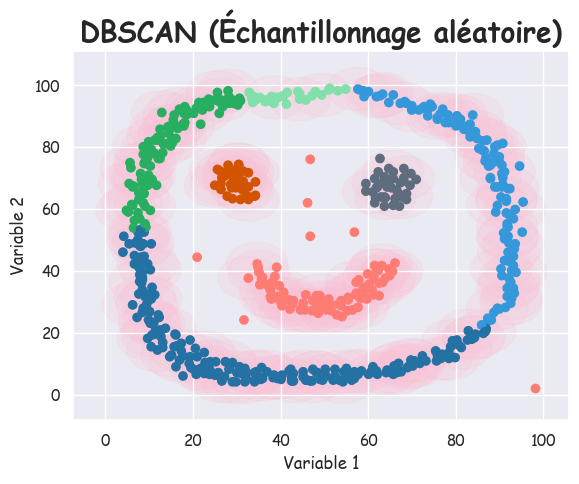

In [10]:
# Supposons que X soit ton jeu de données (tableau NumPy) et n le nombre de points de données
n = len(X)
epsilon = 7
m = 200

for j in range(6):
    # Créer un objet DBSCANpp
    dbscan_pp = DBSCANpp(m=m, eps=epsilon, min_pts=2)

    # Ajuster le modèle et obtenir les clusters
    clusters = dbscan_pp.fit(X)

    fig, ax = plt.subplots()

    ax.scatter(X[:, 0], X[:, 1], c=[colors[i] for i in clusters])

    for i in dbscan_pp.S[dbscan_pp.core_points]:
        circle1 = plt.Circle((i[0], i[1]), epsilon, color='#fcc2d7', alpha=0.2, zorder=0)
        ax.add_patch(circle1)

    plt.title("DBSCAN (Échantillonnage aléatoire)", fontsize=20, weight="bold")
    plt.xlabel("Variable 1")
    plt.ylabel("Variable 2")
    plt.show()

### 4.2 Échantillonnage par k-centres (6 essais)

Avec 140 points choisis par k-centres, le visage est presque toujours bien reconstitué. Il peut arriver qu'un essai rate : l'initialisation k-centres démarre d'un point tiré au hasard et peut donc varier.

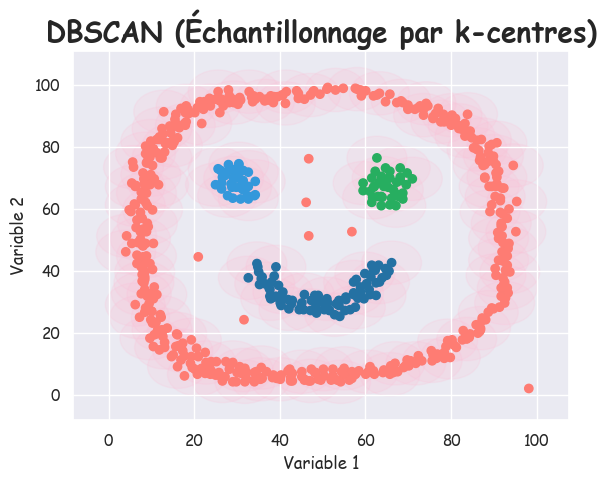

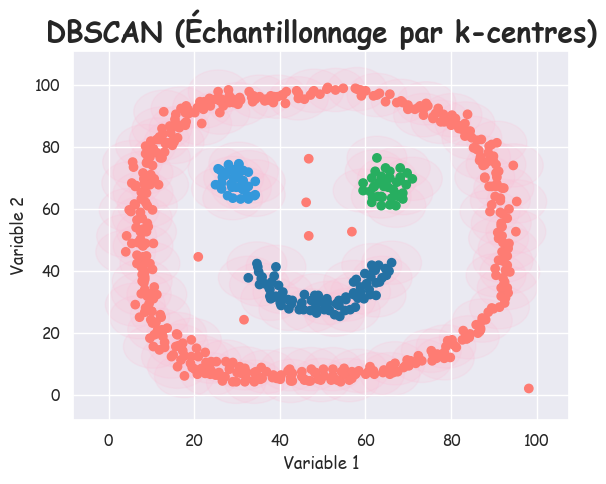

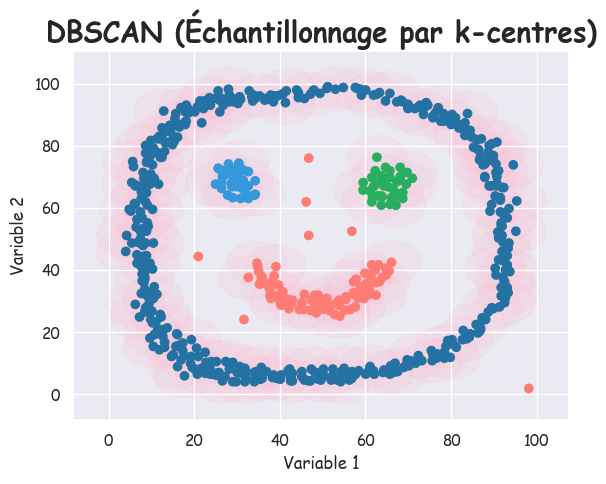

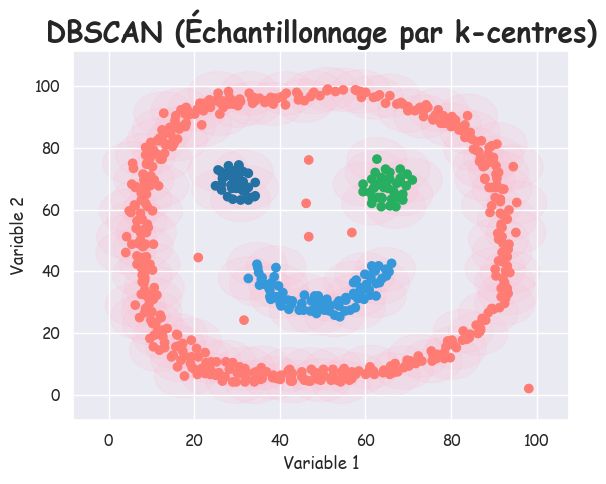

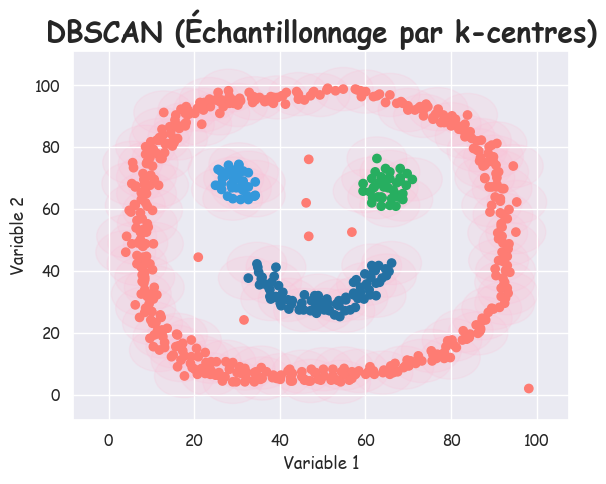

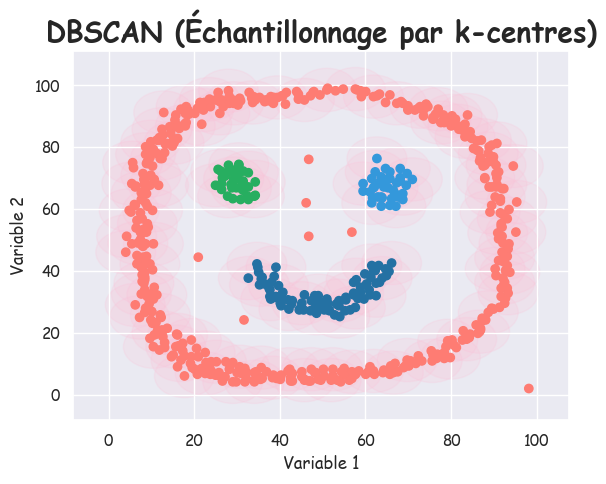

In [11]:
# Supposons que X soit ton jeu de données (tableau NumPy) et n le nombre de points de données
n = len(X)
epsilon = 7
m = 140

for j in range(6):
    # Créer un objet DBSCANpp
    dbscan_pp = DBSCANpp(m=m, eps=epsilon, min_pts=2, sampling="kcenter")

    # Ajuster le modèle et obtenir les clusters
    clusters = dbscan_pp.fit(X)

    fig, ax = plt.subplots()

    ax.scatter(X[:, 0], X[:, 1], c=[colors[i] for i in clusters])

    for i in dbscan_pp.S[dbscan_pp.core_points]:
        circle1 = plt.Circle((i[0], i[1]), epsilon, color='#fcc2d7', alpha=0.2, zorder=0)
        ax.add_patch(circle1)

    plt.title("DBSCAN (Échantillonnage par k-centres)", fontsize=20, weight="bold")
    plt.xlabel("Variable 1")
    plt.ylabel("Variable 2")
    plt.show()

## 5. Pourquoi DBSCAN pose problème à grande échelle

On mesure le temps d'exécution de DBSCAN (scikit-learn) sur des jeux de données « Moons » de 100 à 25 600 points, en moyenne sur 5 essais. Le temps croît de façon **quadratique** avec le nombre de points : c'est ce que DBSCAN++ cherche à éviter.

In [12]:
from tqdm import tqdm
from time import time

datasizes = [100, 200, 400, 1600, 3200, 6400, 12800, 25600]
epsilon = 0.3
runs = 5
times = []
for size in tqdm(datasizes):
    X, y = make_moons(n_samples=size, noise=0.05, random_state=42)
    
    total_time = 0
    
    start = time()
    for i in range(runs):
        dbscan = DBSCAN(eps=epsilon, min_samples=5).fit_predict(X)
    
    times.append([size, (time()-start)/runs])

times = np.array(times)

100%|█████████████████████████████████████████████| 8/8 [00:05<00:00,  1.45it/s]


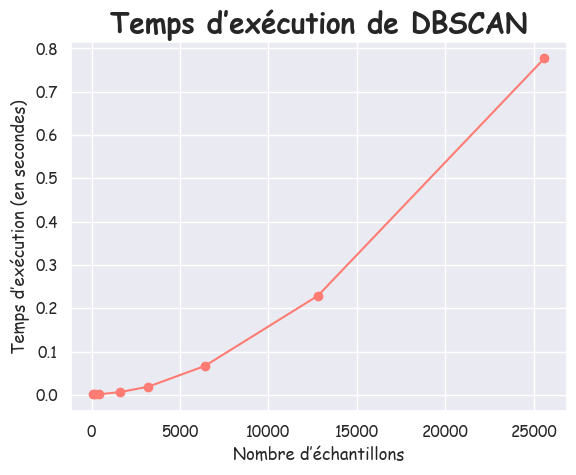

In [13]:
fig, ax = plt.subplots()

ax.plot(times[:, 0], times[:, 1], c=colors[0], marker="o")

ax.set_title("Temps d’exécution de DBSCAN", fontsize=20, weight="bold")
ax.set_xlabel("Nombre d’échantillons")
ax.set_ylabel("Temps d’exécution (en secondes)")
plt.show()

---

## Pour aller plus loin

- [HDBSCAN : la version surpuissante de DBSCAN](https://www.monshotdata.com/p/hdbscan-clustering-densites-variables-dbscan) — l'évolution hiérarchique de DBSCAN
- [Comprendre les Modèles de Mélange Gaussien (GMMs)](https://www.monshotdata.com/p/modeles-melange-gaussien-gmm) — un clustering probabiliste
- [Score de silhouette vs méthode du coude : un choix évident](https://www.monshotdata.com/p/score-de-silhouette-vs-methode-du-coude) — évaluer la qualité d'un clustering